<a href="https://colab.research.google.com/github/Gaurav1764/Gen-AI-Lab4/blob/main/Lab4_Multimodal_Prompt_to_Image.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K.R. Mangalam University | MCA | ETMMGA304 Generative AI and Its Applications
## Lab 4: Multimodal Prompt-to-Image Generation
**Bloom's level:** BTX 3 Apply, BTX 4 Analyze, BTX 5 Evaluate

| Lab record field | Entry |
|---|---|
| Student name / roll no. | Gaurav Kumar (2501940033) |
| Experiment title | Lab 4: Multimodal Prompt-to-Image Generation |
| Date | 22/11/2026 |
| Aim | Generate images from text with Stable Diffusion; change one prompt element while keeping seed and generation settings matched. |
| Software used | Python, PyTorch, Diffusers, Transformers (Google Colab, GPU required) |
| Dataset / model identifier | stable-diffusion-v1-5/stable-diffusion-v1-5 (Hugging Face) |
| Parameters | 512x512, 25 inference steps, guidance 7.5, float16, seeds 42 and 43 |
| Seed | 42 |

> Run the **Common Setup** cell first, then every cell in order. Keep your *own* losses, samples and screenshots. Download this notebook and the files in `lab_outputs` before the session ends.

> **Run this lab in a fresh GPU session** (Runtime > Change runtime type > GPU) to avoid out-of-memory errors.

## Common Setup

In [1]:
from pathlib import Path
import random
import torch
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
out = Path("lab_outputs")
out.mkdir(exist_ok=True)
print("Device:", device)

# Lab record: environment details (copy these into your record)
import sys, platform, datetime
print("Date        :", datetime.date.today())
print("Python      :", sys.version.split()[0], "|", platform.platform())
print("PyTorch     :", torch.__version__)
print("Device      :", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU")
print("Seed        :", SEED)

Device: cuda
Date        : 2026-11-23
Python      : 3.13.16 | Linux-6.6.159+-x86_64-with-glibc2.39
PyTorch     : 2.14.1+cu130
Device      : cuda | Tesla T4
Seed        : 42


## How it works
The model encodes the text and uses it to guide a series of **denoising** steps. Starting noise and wording both influence the image. Using the **same seed and settings** makes prompt comparisons easier within one model and runtime.

`Prompt and seed -> Text guidance -> Iterative denoising -> Decode -> Image`

*Provider options in the syllabus:* Stable Diffusion via Replicate or the DALL-E API. This notebook uses local Diffusers. If you use Replicate instead, record the model version, prompts, seed and available settings, and compare only outputs from the same backend.

## Step 1: Load Stable Diffusion (separate install cell first)

In [2]:
%pip install -q "diffusers>=0.33,<1" "transformers>=4.51,<5" accelerate safetensors

from diffusers import StableDiffusionPipeline
from IPython.display import display

assert device.type == "cuda", "Select a GPU runtime and rerun setup."
repo = "stable-diffusion-v1-5/stable-diffusion-v1-5"
pipe = StableDiffusionPipeline.from_pretrained(repo, torch_dtype=torch.float16)
pipe = pipe.to(device)
pipe.enable_attention_slicing()

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

config.json: 0.00B [00:00, ?B/s]

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

... (9 outputs left out)

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

unet/diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

## Step 2: Compare prompt variants (only the style words differ; seeds 42 and 43)

  0%|          | 0/25 [00:00<?, ?it/s]

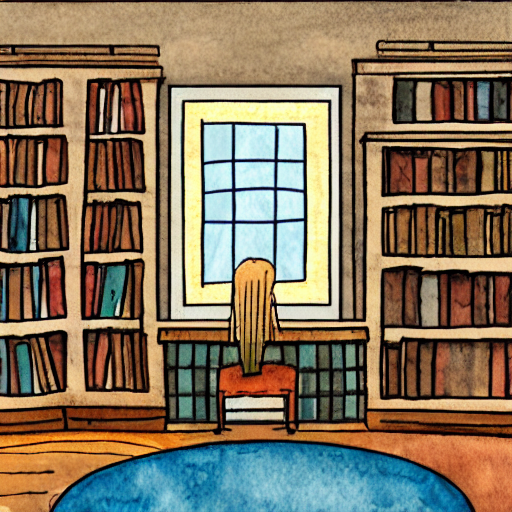

  0%|          | 0/25 [00:00<?, ?it/s]

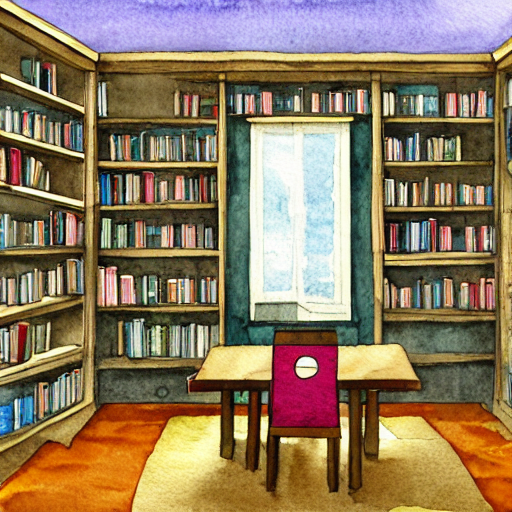

  0%|          | 0/25 [00:00<?, ?it/s]

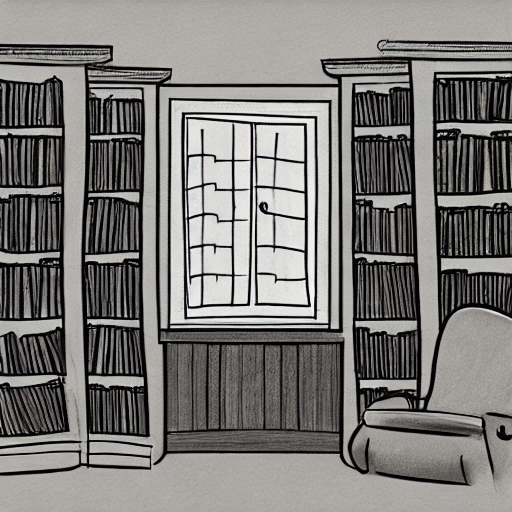

  0%|          | 0/25 [00:00<?, ?it/s]

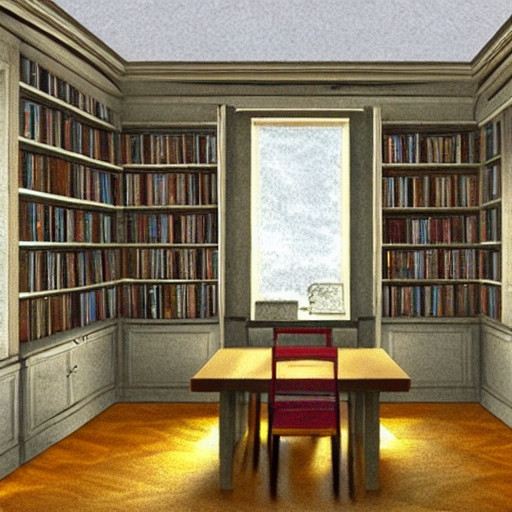

In [3]:
prompts = [
    "A small library with a reading table, wide view, watercolor illustration",
    "A small library with a reading table, wide view, pencil sketch",
]
for i, prompt in enumerate(prompts, 1):
    for seed in (42, 43):
        rng = torch.Generator(device=device).manual_seed(seed)
        result = pipe(prompt, width=512, height=512,
                      num_inference_steps=25, guidance_scale=7.5, generator=rng)
        flags = result.nsfw_content_detected
        if flags and flags[0]:
            print("Image flagged. Review the classroom prompt.")
            continue
        image = result.images[0]
        image.save(out / f"library_prompt_{i}_seed_{seed}.png")
        display(image)

### Four-image contact sheet (handy for your record)
Files: `library_prompt_1_seed_42/43.png` (watercolor), `library_prompt_2_seed_42/43.png` (pencil sketch).

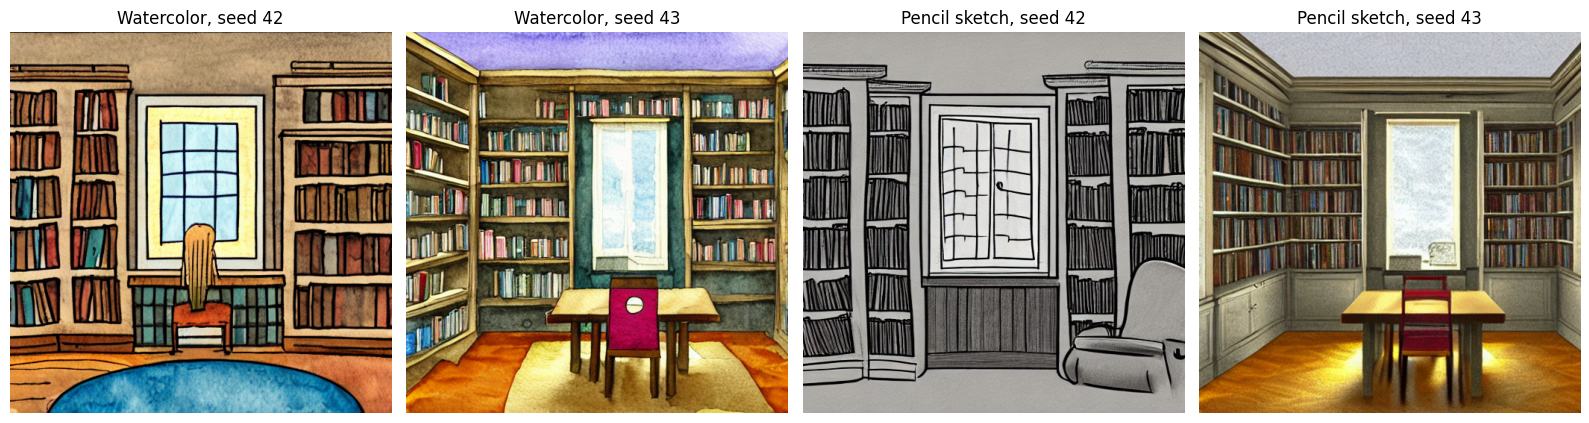

In [4]:
from PIL import Image
names = [("Watercolor", 42, "library_prompt_1_seed_42.png"), ("Watercolor", 43, "library_prompt_1_seed_43.png"),
         ("Pencil sketch", 42, "library_prompt_2_seed_42.png"), ("Pencil sketch", 43, "library_prompt_2_seed_43.png")]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for ax, (style, seed, fn) in zip(axes, names):
    p = out / fn
    if p.exists():
        ax.imshow(Image.open(p))
    else:
        ax.text(0.5, 0.5, "missing / flagged", ha="center")
    ax.set_title(f"{style}, seed {seed}"); ax.axis("off")
plt.tight_layout(); plt.savefig(out / "library_contact_sheet.png", bbox_inches="tight"); plt.show()

## Observation table
Score each image **independently** for subject and style: **0 = missing, 1 = partial, 2 = clear adherence**. Note composition issues or errors (e.g. warped furniture, extra objects, text artifacts).

In [5]:
import pandas as pd
table = pd.DataFrame({
    "Style requested": ["Watercolor", "Watercolor", "Pencil sketch", "Pencil sketch"],
    "Seed": [42, 43, 42, 43],
    "Subject score 0-2": [None] * 4,      # library + reading table
    "Style score 0-2": [None] * 4,
    "Composition or errors": [""] * 4,
})
# --- EDIT: enter your own scores, e.g. table.loc[0, "Subject score 0-2"] = 2 ---
table.to_csv(out / "sd_observation_table.csv", index=False)
display(table)
print("Files saved:", sorted(p.name for p in out.iterdir()))

,Style requested,Seed,Subject score 0-2,Style score 0-2,Composition or errors
0,Watercolor,42,None,None,
1,Watercolor,43,None,None,
2,Pencil sketch,42,None,None,
3,Pencil sketch,43,None,None,


Files saved: ['library_contact_sheet.png', 'library_prompt_1_seed_42.png', 'library_prompt_1_seed_43.png', 'library_prompt_2_seed_42.png', 'library_prompt_2_seed_43.png', 'sd_observation_table.csv']


## Result and submission
Submit the **four images** and the **completed table**. In your discussion state:
* which visual features change with **style** (e.g. colours, line quality, texture) and which change across **seeds** (e.g. layout, object placement, viewpoint);
* **one useful application** (e.g. concept art, study material illustrations);
* **one risk** related to bias, misleading imagery or source permissions.

**Disclosure text you can adapt:** *"This image was generated by an AI model (Stable Diffusion v1.5) from a text prompt and has not been photographed or drawn by a person."*

## Viva questions: draft answers
1. **Why compare prompt variants at the same seed?** The seed fixes the starting noise, so differences between images come from the wording change rather than random variation.
2. **Purpose of denoising steps?** The image starts as noise and each step removes some noise guided by the text embedding, gradually forming a coherent image.
3. **Rating subject and style independently?** Check first whether the requested subject (library, reading table) is present, then separately whether the requested medium (watercolor / pencil sketch) is visible; one can succeed while the other fails.
4. **When should a generated image carry a disclosure?** Whenever it could be mistaken for a real photograph or human work, is published or submitted, or used in teaching, news or any context where origin matters.

In [ ]:
# Download everything for submission (works in Colab; elsewhere files stay in lab_outputs/)
import shutil
shutil.make_archive("lab_outputs_submission", "zip", "lab_outputs")
try:
    from google.colab import files
    files.download("lab_outputs_submission.zip")
except ImportError:
    print("Not in Colab. Collect the zip: lab_outputs_submission.zip")